# 05 · Análisis de sensibilidad y robustez

**Objetivo.** Evaluar si las conclusiones de 04 dependen de decisiones de modelación o de supuestos no verificables.

**Justificación.** Un efecto creíble debe sobrevivir a especificaciones alternativas razonables y estar acompañado de una evaluación honesta de lo que pasaría si los supuestos no comprobables fallaran. Se revisan cuatro frentes:

| Frente | Amenaza | Herramienta |
|---|---|---|
| 5.1 Especificación | El resultado depende del modelo o de un centro | Estimador de Lin, logit, diferencias, recorte de extremos, excluir un centro a la vez |
| 5.2 Faltantes de ingreso | Los faltantes no son aleatorios (MNAR) | IPW, cotas de Lee, cotas de Manski, ajuste delta y punto de quiebre |
| 5.3 Margen intensivo | Colisionador al condicionar en el empleo | Cotas de Lee [1] |
| 5.4 Supuestos del IV | Violaciones de exclusión o monotonicidad | Implicancias comprobables; LATE en función de un efecto directo $\gamma$ |

> **En sencillo — análisis de sensibilidad:** consiste en preguntar "¿y si me equivoqué en este supuesto?" y recalcular. Si la conclusión se mantiene aunque se cambien los supuestos dentro de rangos razonables, es **robusta**. Si cambia con poco, es frágil y hay que decirlo.

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

In [2]:
# Base analítica generada en 01_datos_auditoria_construccion.ipynb
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe la base analítica. Ejecute primero 01_datos_auditoria_construccion.ipynb"
    )
df = pd.read_csv(PROCESSED)
print(f"Base analítica: {df.shape[0]} filas x {df.shape[1]} columnas")

Base analítica: 1500 filas x 28 columnas


In [3]:
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

NOMBRES = {"empleo_post": "Empleo (pp)", "horas_post": "Horas semanales",
           "ingreso_post_c": "Ingreso mensual", "bienestar_post": "Bienestar (0-100)"}
ESCALA = {"empleo_post": 100}
CTRL = f"C({CENTER}) + " + " + ".join(BASELINE)

def itt_m3(data, y, extra=""):
    # ITT principal (M3) con HC3; devuelve (efecto, ee) en la escala de reporte
    m = smf.ols(f"{y} ~ {Z} + {CTRL}{extra}", data=data.dropna(subset=[y])).fit(cov_type="HC3")
    e = ESCALA.get(y, 1)
    return e * m.params[Z], e * m.bse[Z]

def bootstrap_estratificado(data, rng):
    # Remuestreo con reposición dentro de cada celda centro × Z (respeta el diseño)
    partes = [g.sample(len(g), replace=True, random_state=rng.integers(1e9))
              for _, g in data.groupby([CENTER, Z])]
    return pd.concat(partes, ignore_index=True)

rng = np.random.default_rng(SEED)

## 5.1 Robustez de especificación

**Fundamento metodológico**

- **Estimador de Lin** [2]: interactúa $Z$ con covariables centradas (restándoles su media). Así permite que la relación entre covariables y resultado sea distinta en cada grupo. Con muestras grandes nunca es menos preciso que la diferencia de medias, aunque el modelo lineal esté mal especificado. Responde a la crítica de Freedman [3] al ajuste por MCO.
- **Logit (efecto marginal promedio):** comprueba que el modelo lineal de probabilidad no distorsione el efecto sobre el empleo, que es binario.
  > **En sencillo:** el **logit** es un modelo pensado para resultados sí/no que nunca predice probabilidades fuera de 0-1. El **efecto marginal promedio** traduce su resultado a puntos porcentuales para compararlo con la regresión lineal.
- **Resultado en diferencias** ($Y_{post} - Y_{pre}$, con efectos fijos de centro): otra forma de usar la línea base. Con buen balance debería dar un resultado similar a M3. Equivale a imponer un coeficiente de 1 sobre la línea base, en lugar de estimarlo.
- **Ingreso winsorizado al percentil 99** (los valores por encima del p99 se reemplazan por el p99, sin eliminar a nadie) e **ingreso original sin imputación lógica:** sensibilidad a valores altos y a la regla de 01.
- **Excluir un centro a la vez:** verifica que ningún centro explique el resultado por sí solo.

In [4]:
filas = []
# Lin: covariables (y dummies de centro) centradas e interactuadas con Z
dummies = pd.get_dummies(df[CENTER], prefix="c", drop_first=True, dtype=float)
lin_df = pd.concat([df, dummies], axis=1)
covs_lin = BASELINE + list(dummies.columns)
for v in covs_lin:
    lin_df[f"{v}_c"] = lin_df[v] - lin_df[v].mean()
f_lin = " + ".join(f"{Z} * {v}_c" for v in covs_lin)

for y in OUTCOMES:
    e = ESCALA.get(y, 1)
    b, se = itt_m3(df, y); filas.append((y, "M3 principal", b, se))
    m = smf.ols(f"{y} ~ {f_lin}", data=lin_df.dropna(subset=[y])).fit(cov_type="HC3")
    filas.append((y, "Lin (interactuado)", e * m.params[Z], e * m.bse[Z]))

# Logit para empleo: efecto marginal promedio de Z
lg = smf.logit(f"empleo_post ~ {Z} + {CTRL}", data=df).fit(disp=0)
mg = lg.get_margeff(at="overall", method="dydx", dummy=True).summary_frame().loc[Z]
filas.append(("empleo_post", "Logit (efecto marginal)", 100 * mg["dy/dx"], 100 * mg["Std. Err."]))

# Resultados en diferencias (solo efectos fijos de centro: si se controla por la línea base,
# el coeficiente es idéntico a M3 por construcción)
for y, dy in [("empleo_post", "d_empleo"), ("horas_post", "d_horas"), ("ingreso_post_c", "d_ingreso")]:
    m = smf.ols(f"{dy} ~ {Z} + C({CENTER})", data=df.dropna(subset=[dy])).fit(cov_type="HC3")
    e = ESCALA.get(y, 1)
    filas.append((y, "Resultado en diferencias", e * m.params[Z], e * m.bse[Z]))

# Ingreso: recorte al p99 e ingreso original sin imputación lógica
p99 = df["ingreso_post_c"].quantile(0.99)
filas.append(("ingreso_post_c", "Winsorizado al p99",
              *itt_m3(df.assign(ingreso_post_c=df["ingreso_post_c"].clip(upper=p99)), "ingreso_post_c")))
filas.append(("ingreso_post_c", "Original (58 faltantes)", *itt_m3(df, "ingreso_post")))

robustez = pd.DataFrame(filas, columns=["resultado", "especificación", "itt", "ee"])
robustez["ic_inf"], robustez["ic_sup"] = robustez["itt"] - 1.96 * robustez["ee"], robustez["itt"] + 1.96 * robustez["ee"]
display(robustez.set_index(["resultado", "especificación"]))

itt     ee  ic_inf  ic_sup
resultado      especificación                                         
empleo_post    M3 principal               9.661  2.481   4.797  14.524
               Lin (interactuado)         9.664  2.490   4.785  14.544
horas_post     M3 principal               5.486  0.936   3.653   7.320
               Lin (interactuado)         5.490  0.938   3.652   7.329
ingreso_post_c M3 principal             188.807 37.249 115.800 261.815
               Lin (interactuado)       188.793 37.397 115.494 262.092
bienestar_post M3 principal               3.421  0.528   2.386   4.456
               Lin (interactuado)         3.422  0.532   2.379   4.465
empleo_post    Logit (efecto marginal)    9.629  2.455   4.818  14.440
               Resultado en diferencias   8.961  3.402   2.294  15.628
horas_post     Resultado en diferencias   5.524  1.111   3.347   7.700
ingreso_post_c Resultado en diferencias 183.103 48.294  88.447 277.759
               Winsorizado al p99       186.843 37.156 114.018 259.668
               Original (58 faltantes)  181.449 37.289 108.363 254.536

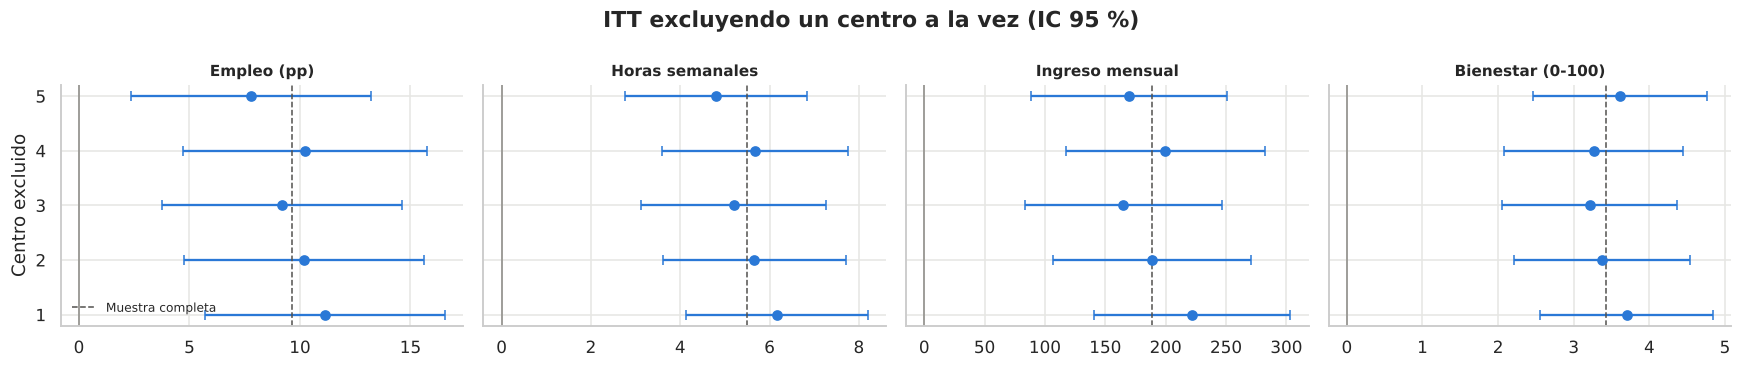

resultado,bienestar_post,empleo_post,horas_post,ingreso_post_c
centro_excluido,,,,
1,3.698,11.145,6.166,221.917
2,3.370,10.170,5.658,188.465
3,3.213,9.187,5.196,164.721
4,3.263,10.223,5.673,199.834
5,3.608,7.779,4.808,169.931


In [5]:
# Excluir un centro a la vez
loo = []
for c in sorted(df[CENTER].unique()):
    for y in OUTCOMES:
        b, se = itt_m3(df[df[CENTER] != c], y)
        loo.append({"centro_excluido": c, "resultado": y, "itt": b, "ee": se})
loo = pd.DataFrame(loo)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, y in zip(axes, OUTCOMES):
    sub = loo[loo["resultado"] == y]
    base, _ = itt_m3(df, y)
    ax.errorbar(sub["itt"], sub["centro_excluido"], xerr=1.96 * sub["ee"], fmt="o", color=COLORS[1], capsize=3)
    ax.axvline(base, color="#52514e", lw=1, ls="--", label="Muestra completa")
    ax.axvline(0, color=NEUTRAL, lw=1)
    ax.set_title(NOMBRES[y], fontsize=10)
axes[0].set_ylabel("Centro excluido"); axes[0].legend(frameon=False, fontsize=8, loc="lower left")
plt.suptitle("ITT excluyendo un centro a la vez (IC 95 %)", fontweight="bold")
plt.tight_layout(); plt.show()
display(loo.pivot(index="centro_excluido", columns="resultado", values="itt"))

**Interpretación**

- **El efecto no depende del modelo.** Lin, M3 y logit dan prácticamente el mismo punto (empleo 9.6-9.7 pp). El modelo lineal de probabilidad no distorsiona el resultado binario. No hay indicios de sesgo de Freedman en el ajuste por MCO.
- **Diferencias:** puntos similares (empleo 9.0 pp, horas 5.5, ingreso 183) pero errores estándar mayores. La línea base no se correlaciona perfectamente con el resultado, y estimar su coeficiente (M3) es más eficiente que imponerle 1.
- **Ingreso:** winsorizar al p99 (187) o usar el ingreso original con 58 faltantes (181) no cambia la conclusión. El resultado no depende de valores extremos ni de la regla de imputación lógica.
- **Por centro:** sin ningún centro el efecto se mantiene positivo y significativo en los cuatro resultados. El rango para empleo va de 7.8 pp (sin el centro 5) a 11.1 pp (sin el centro 1). Ningún centro explica el resultado por sí solo.

## 5.2 Faltantes del ingreso

Después de la imputación lógica (01) faltan 39 ingresos (2.6 %), todos de madres empleadas: 20 sin oferta y 19 con oferta. En 02.7 la atrición resultó no diferencial y no predicha por $X$, lo que es compatible con faltantes al azar. Se evalúa qué pasaría si no lo fueran:

| Método | Supuesto sobre los faltantes | Resultado |
|---|---|---|
| Casos completos (M3) | MAR: el faltante no depende del propio ingreso, dadas $Z$, $X$ y el centro | Estimación puntual |
| IPW | El mismo supuesto (MAR), modelado de otra forma: sirve como comprobación | Estimación puntual corregida |
| Cotas de Lee [1] | Monotonicidad de la observación respecto de $Z$ | Intervalo de identificación (más estrecho) |
| Cotas de Manski [4] | Solo que el ingreso faltante está entre 0 y el máximo observado (2 763 u.m.) | Intervalo de identificación (peor caso) |
| Ajuste delta / punto de quiebre | MNAR con desviación $\delta$ | Cuánto MNAR se necesitaría para anular el efecto |

### 5.2.1 Ponderación por la inversa de la probabilidad de observación (IPW)

**Fundamento.** Se modela $\pi_i = P(R_i = 1 \mid Z_i, X_i, C_i)$ con un logit, y se pondera a las observadas por $1/\hat\pi_i$. Así, quienes se parecen a las que faltan pesan más. El IC se obtiene por **bootstrap estratificado** que reestima el modelo de observación en cada réplica, para incorporar la incertidumbre de los pesos.

> **En sencillo — IPW:** si entre las madres con ingreso observado faltan "tipos" de madres (por ejemplo, las de menor educación pierden más el dato), se les da más peso a las de ese tipo que sí tienen dato, para que "representen" también a las que faltan. Una madre con 50 % de probabilidad de tener dato cuenta doble.
>
> **En sencillo — bootstrap:** para saber cuánto variaría un resultado, se crean cientos de muestras nuevas sacando madres al azar *con reposición* de la base original y se recalcula todo en cada una. La dispersión de esos resultados da el margen de error. Es **estratificado** porque se remuestrea dentro de cada combinación centro × sorteo, respetando el diseño original.

In [6]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
# Con solo 39 faltantes, algunas réplicas bootstrap no tienen faltantes en alguna celda
# (separación casi completa); el logit avisa que no converge, pero las predicciones son válidas.
warnings.simplefilter("ignore", ConvergenceWarning)

f_resp = f"R_ingreso ~ {Z} + {CTRL}"

def itt_ipw(data):
    # Reestima los pesos 1/P(R=1|Z,X,C) y el ITT ponderado del ingreso
    p = smf.logit(f_resp, data=data).fit(disp=0).predict(data)
    obs = data[data["R_ingreso"] == 1].assign(w=1 / p[data["R_ingreso"] == 1])
    return smf.wls(f"ingreso_post_c ~ {Z} + {CTRL}", data=obs, weights=obs["w"]).fit().params[Z], obs["w"]

ipw_est, pesos = itt_ipw(df)
print(f"Pesos IPW: mín {pesos.min():.3f}, p99 {pesos.quantile(.99):.3f}, máx {pesos.max():.3f}")
boot_ipw = np.array([itt_ipw(bootstrap_estratificado(df, rng))[0] for _ in range(500)])
cc_est, cc_se = itt_m3(df, "ingreso_post_c")
print(f"ITT casos completos: {cc_est:.1f}  (IC95 {cc_est - 1.96 * cc_se:.1f} a {cc_est + 1.96 * cc_se:.1f})")
print(f"ITT IPW:             {ipw_est:.1f}  (IC95 bootstrap {np.percentile(boot_ipw, 2.5):.1f} a {np.percentile(boot_ipw, 97.5):.1f})")

Pesos IPW: mín 1.004, p99 1.087, máx 1.178


ITT casos completos: 188.8  (IC95 115.8 a 261.8)
ITT IPW:             188.5  (IC95 bootstrap 115.4 a 260.9)


**Interpretación.** Los pesos son casi uniformes (1.00 a 1.18), porque la observación del ingreso apenas depende de $Z$ y $X$ (02.7). Por eso el ITT con IPW (188.5, IC95 115-261) es prácticamente igual al de casos completos (188.8). Si los faltantes son MAR, no hay sesgo por atrición. La limitación es la de siempre: el IPW no corrige si el faltante depende del propio ingreso no observado (MNAR). Para eso están las secciones siguientes.

### 5.2.2 Cotas de Lee y de Manski

**Fundamento** [1]. Si la oferta solo puede aumentar, o solo disminuir, la probabilidad de observar el ingreso (monotonicidad), el grupo con mayor tasa de observación contiene una fracción $p = |q_1 - q_0| / \max(q_1, q_0)$ de casos "extra". Se recorta esa fracción por arriba y por abajo de su distribución, y se obtienen las cotas inferior y superior del efecto para quienes se observarían en cualquier grupo. El IC se obtiene por bootstrap estratificado.

> **En sencillo — cotas (intervalo de identificación):** cuando faltan datos y no se sabe por qué, a veces no se puede calcular *un* efecto, pero sí un rango donde *tiene* que estar. Si todo el rango es positivo, se sabe que el efecto es positivo aunque no se conozca su valor exacto. Las **cotas de Lee** suponen que el sorteo solo empuja en una dirección la probabilidad de tener el dato, y "recortan" del grupo con más datos a las personas que sobran, en el escenario más pesimista (se quitan las de valores altos) y en el más optimista (se quitan las de valores bajos).

**Fundamento** [4]. Sin supuestos sobre el mecanismo del faltante (solo sobre el rango posible del ingreso), se imputan a los faltantes los extremos del soporte (0 y el máximo observado) en la dirección más desfavorable y en la más favorable.

> **En sencillo — cotas de Manski:** es el análisis "del peor caso": a las sorteadas que faltan se les asigna el peor ingreso posible (0) y a las no sorteadas que faltan el mejor posible (el máximo). Si aun así el efecto es positivo, ningún patrón de faltantes con ingresos entre 0 y 2 763 u.m. podría anularlo.

In [7]:
def lee_bounds(data, y, sel):
    # Cotas de Lee (2009) para el efecto de Z sobre y, con selección sel (1 = observado/seleccionado)
    q1 = data.loc[data[Z] == 1, sel].mean()
    q0 = data.loc[data[Z] == 0, sel].mean()
    g_rec = 1 if q1 >= q0 else 0                      # grupo que se recorta
    p = abs(q1 - q0) / max(q1, q0)
    y_rec = np.sort(data.loc[(data[Z] == g_rec) & (data[sel] == 1), y].dropna().to_numpy())
    y_otro = data.loc[(data[Z] != g_rec) & (data[sel] == 1), y].dropna().mean()
    k = int(np.ceil(p * len(y_rec)))                 # redondeo hacia arriba: conservador
    sin_altos = y_rec[: len(y_rec) - k].mean()        # recorta los valores más altos
    sin_bajos = y_rec[k:].mean()                      # recorta los valores más bajos
    if g_rec == 1:
        return sin_altos - y_otro, sin_bajos - y_otro, p
    return y_otro - sin_bajos, y_otro - sin_altos, p

lee_inf, lee_sup, p_rec = lee_bounds(df, "ingreso_post_c", "R_ingreso")
boot = np.array([lee_bounds(bootstrap_estratificado(df, rng), "ingreso_post_c", "R_ingreso")[:2] for _ in range(500)])
print(f"Proporción recortada: {100 * p_rec:.2f} %")
print(f"Cotas de Lee: [{lee_inf:.1f}, {lee_sup:.1f}]  IC95 bootstrap: [{np.percentile(boot[:, 0], 2.5):.1f}, {np.percentile(boot[:, 1], 97.5):.1f}]")

# Manski: peor y mejor caso imputando los extremos del soporte a los faltantes
y_max = df["ingreso_post_c"].max()
falta = df["ingreso_post_c"].isna()
peor = df.assign(ingreso_post_c=np.where(falta, np.where(df[Z] == 1, 0, y_max), df["ingreso_post_c"]))
mejor = df.assign(ingreso_post_c=np.where(falta, np.where(df[Z] == 1, y_max, 0), df["ingreso_post_c"]))
def dif_medias(data, y):
    return data.loc[data[Z] == 1, y].mean() - data.loc[data[Z] == 0, y].mean()

print(f"Cotas de Manski (diferencia de medias, forma clásica): [{dif_medias(peor, 'ingreso_post_c'):.1f}, {dif_medias(mejor, 'ingreso_post_c'):.1f}]")
print(f"Cotas de Manski con ajuste M3 (complementario):        [{itt_m3(peor, 'ingreso_post_c')[0]:.1f}, {itt_m3(mejor, 'ingreso_post_c')[0]:.1f}]")

Proporción recortada: 0.13 %
Cotas de Lee: [181.2, 184.9]  IC95 bootstrap: [93.0, 262.9]
Cotas de Manski (diferencia de medias, forma clásica): [106.4, 250.0]
Cotas de Manski con ajuste M3 (complementario):        [112.1, 253.5]


**Interpretación**

- **Lee:** las tasas de observación son casi idénticas (97.3 % frente a 97.5 %), así que la fracción a recortar es 0.13 %, una sola observación. Las cotas prácticamente colapsan en **[181, 185]**, alrededor de la diferencia de medias sin ajustar (184), con IC95 bootstrap [93, 263], que excluye el cero.
- **Manski:** aun con el **peor caso posible** (todas las sorteadas que faltan ganan 0 y todas las no sorteadas que faltan ganan el máximo observado, 2 763 u.m.), el efecto sigue siendo **positivo: [106, 250]** en diferencia de medias, que es la forma clásica, y [112, 254] con el ajuste M3. La atrición es tan pequeña que ni el supuesto más extremo cambia el signo de la conclusión.

### 5.2.3 Ajuste delta y punto de quiebre

**Fundamento.** Se imputa a cada faltante su ingreso predicho por un modelo de las empleadas observadas ($\hat Y_i$), más una desviación hipotética según el grupo: $Y_i^{imp} = \max(0, \hat Y_i + \delta_z)$. Se recorre una grilla de $\delta_0$ (sin oferta) y $\delta_1$ (con oferta) en múltiplos de la desviación estándar del ingreso de las empleadas. El escenario más adverso para la conclusión es $\delta_1 < 0 < \delta_0$: las sorteadas que faltan ganan menos de lo predicho y las no sorteadas, más.

> **En sencillo — ajuste delta y punto de quiebre:** se completa cada ingreso faltante con lo que predice un modelo y luego se lo "castiga" o "premia" a propósito con una cantidad $\delta$, distinta según el grupo. El **punto de quiebre** es el castigo necesario para que el efecto desaparezca. Si para anularlo hay que suponer desviaciones absurdas, la conclusión es robusta.

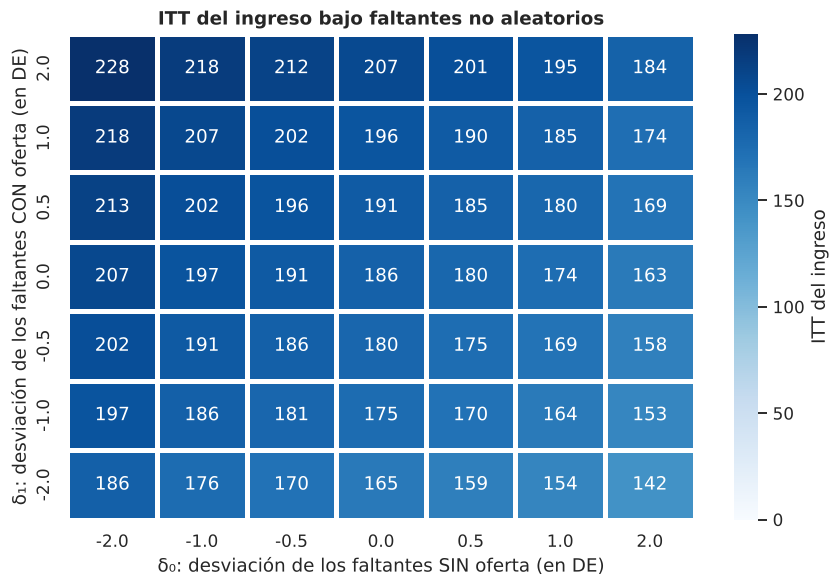

DE del ingreso de las empleadas: 421
Escenario más adverso (δ₁ = −2 DE, δ₀ = +2 DE): ITT = 142.4, IC95 inferior = 69.4


In [8]:
emp_obs = df[(df["empleo_post"] == 1) & df["ingreso_post_c"].notna()]
modelo_pred = smf.ols(f"ingreso_post_c ~ {Z} + {CTRL}", data=emp_obs).fit()
falta = df["ingreso_post_c"].isna()
pred = modelo_pred.predict(df.loc[falta])
sd_emp = emp_obs["ingreso_post_c"].std()

def itt_delta(d0, d1):
    imp = np.maximum(0, pred + np.where(df.loc[falta, Z] == 1, d1, d0))
    datos = df.copy(); datos.loc[falta, "ingreso_post_c"] = imp
    b, se = itt_m3(datos, "ingreso_post_c")
    return b, b - 1.96 * se

mult = np.array([-2, -1, -0.5, 0, 0.5, 1, 2])
grid = pd.DataFrame([(m0, m1, *itt_delta(m0 * sd_emp, m1 * sd_emp)) for m0 in mult for m1 in mult],
                    columns=["delta0_DE", "delta1_DE", "itt", "ic_inf"])
mapa = grid.pivot(index="delta1_DE", columns="delta0_DE", values="itt").sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(mapa, annot=True, fmt=".0f", cmap="Blues", vmin=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "ITT del ingreso"}, ax=ax)
ax.set_xlabel("δ₀: desviación de los faltantes SIN oferta (en DE)")
ax.set_ylabel("δ₁: desviación de los faltantes CON oferta (en DE)")
ax.set_title("ITT del ingreso bajo faltantes no aleatorios")
plt.tight_layout(); plt.show()
print(f"DE del ingreso de las empleadas: {sd_emp:.0f}")
print(f"Escenario más adverso (δ₁ = −2 DE, δ₀ = +2 DE): ITT = {grid.query('delta0_DE == 2 and delta1_DE == -2')['itt'].iloc[0]:.1f}, "
      f"IC95 inferior = {grid.query('delta0_DE == 2 and delta1_DE == -2')['ic_inf'].iloc[0]:.1f}")

**Interpretación.** El ITT del ingreso se mantiene entre 142 y 228 u.m. en toda la grilla. En el escenario más adverso (las sorteadas que faltan ganan 2 DE ≈ 840 u.m. menos de lo predicho, y las no sorteadas 840 más), el efecto es 142, con límite inferior del IC95 de 69. **No hay punto de quiebre dentro de rangos plausibles**, coherente con las cotas de Manski. Con solo 19 y 20 faltantes por grupo, ningún mecanismo MNAR razonable puede anular el efecto.

## 5.3 Margen intensivo: cotas de Lee para horas e ingreso de las empleadas

*Puente con 5.2.2:* allí la "selección" era tener el ingreso registrado. Aquí es **estar empleada**. La herramienta (cotas de Lee) es la misma, pero responde otra pregunta.

**Fundamento metodológico.** La pregunta es si, además de aumentar el empleo, la oferta aumenta las horas y el ingreso **de las madres que trabajarían de todos modos** (*always-employed*). Comparar empleadas con y sin oferta está sesgado, porque las empleadas con oferta incluyen a quienes entraron al empleo por ella (el colisionador de 4.9). Lee [1] acota el efecto para las *always-employed* con dos supuestos: (i) el sorteo, y (ii) **monotonicidad del empleo**: la oferta no hace que ninguna madre deje de trabajar.

La fracción a recortar entre las empleadas con oferta es $p = (q_1 - q_0)/q_1$, donde $q_z$ es la tasa de empleo de cada grupo.

In [9]:
filas = []
for y in ["horas_post", "ingreso_post_c"]:
    d = df if y == "horas_post" else df[df["R_ingreso"] == 1]   # ingreso: entre observadas
    li, ls, p = lee_bounds(d, y, "empleo_post")
    b = np.array([lee_bounds(bootstrap_estratificado(d, rng), y, "empleo_post")[:2] for _ in range(500)])
    ingenuo = d.loc[(d["empleo_post"] == 1) & (d[Z] == 1), y].mean() - d.loc[(d["empleo_post"] == 1) & (d[Z] == 0), y].mean()
    filas.append({"resultado": y, "recorte_%": 100 * p, "ingenuo_entre_empleadas": ingenuo,
                  "cota_inf": li, "cota_sup": ls,
                  "IC95_inf": np.percentile(b[:, 0], 2.5), "IC95_sup": np.percentile(b[:, 1], 97.5)})
lee_int = pd.DataFrame(filas).set_index("resultado")
display(lee_int)

,recorte_%,ingenuo_entre_empleadas,cota_inf,cota_sup,IC95_inf,IC95_sup
resultado,,,,,,
horas_post,14.457,3.022,0.342,5.742,-1.551,7.436
ingreso_post_c,15.116,66.619,-50.636,176.876,-116.921,246.644


**Interpretación**

- La oferta aumenta el empleo de 57 % a 67 %. Entre las empleadas con oferta, aproximadamente 1 de cada 7 (14.5 %) trabaja **por** la oferta. Ese es el grupo que se recorta.
- **Horas:** el efecto sobre las *always-employed* está entre **+0.3 y +5.7 horas semanales**. Las cotas son positivas, pero el IC95 [−1.6, 7.4] incluye el cero. La diferencia ingenua entre empleadas (+3.0) cae dentro del intervalo, pero no tiene interpretación causal por sí sola.
- **Ingreso:** cotas [−51, +177] u.m., IC95 [−117, 247]. No es posible afirmar que la oferta aumente el ingreso de quienes trabajarían de todos modos.

**¿Qué parte del efecto total viene de cada margen?** Bajo monotonicidad del empleo, el ITT sin ajustar se descompone exactamente en dos partes:

$$ITT = \underbrace{q_0 \cdot \Delta_{AE}}_{\text{intensivo: las que trabajarían igual}} + \underbrace{(q_1 - q_0)\cdot E[Y \mid \text{nuevas empleadas}]}_{\text{extensivo: las que trabajan gracias a la oferta}}$$

$q_0$ es la proporción de *always-employed* y $\Delta_{AE}$ su efecto, acotado por Lee. Multiplicar las cotas por $q_0$ da el rango posible del aporte intensivo.

In [10]:
descomp = []
for y in ["horas_post", "ingreso_post_c"]:
    d = df if y == "horas_post" else df[df["R_ingreso"] == 1]
    q0 = d.loc[d[Z] == 0, "empleo_post"].mean()
    itt_crudo = d.loc[d[Z] == 1, y].mean() - d.loc[d[Z] == 0, y].mean()
    lo, hi = q0 * lee_int.loc[y, "cota_inf"], q0 * lee_int.loc[y, "cota_sup"]
    descomp.append({"resultado": y, "ITT_sin_ajuste": itt_crudo, "q0 (always-employed)": q0,
                    "aporte_intensivo_min": lo, "aporte_intensivo_max": hi,
                    "% intensivo mín": 100 * lo / itt_crudo, "% intensivo máx": 100 * hi / itt_crudo})
display(pd.DataFrame(descomp).set_index("resultado"))

,ITT_sin_ajuste,q0 (always-employed),aporte_intensivo_min,aporte_intensivo_max,% intensivo mín,% intensivo máx
resultado,,,,,,
horas_post,5.416,0.570,0.195,3.272,3.598,60.424
ingreso_post_c,183.618,0.558,-28.262,98.721,-15.392,53.764


**Interpretación**

- **El margen extensivo es un canal claro:** la oferta aumenta en 10 pp la proporción de madres que trabajan, y cada una de ellas pasa de 0 a una jornada positiva.
- **El aporte del margen intensivo no está identificado con precisión.** Según las cotas, podría explicar desde casi nada (≈ 4 %) hasta ≈ 60 % del efecto sobre las horas, y desde −15 % hasta ≈ 54 % del efecto sobre el ingreso. **Los datos no permiten decir cuál de los dos márgenes domina.**
- Todo esto depende de la **monotonicidad del empleo** (la oferta no lleva a ninguna madre a dejar de trabajar), algo plausible para un servicio que libera tiempo.

## 5.4 Supuestos de variables instrumentales

### 5.4.1 Monotonicidad (no hay "desafiantes")

**Fundamento.** La monotonicidad no se puede probar directamente, pero implica que la primera etapa debe ser **no negativa en todo subgrupo** definido por características previas. Si en algún subgrupo la oferta *redujera* el uso, sería evidencia de desafiantes. Los **desafiantes** (*defiers*) serían madres que hacen lo contrario de lo que el sorteo empuja. Se calcula $\pi$ en cada centro, en cada categoría de las binarias y en cada tercil de las continuas.

In [11]:
celdas = []
def fs(g):
    return g.loc[g[Z] == 1, D].mean() - g.loc[g[Z] == 0, D].mean()

for c, g in df.groupby(CENTER):
    celdas.append(("centro", c, len(g), fs(g)))
for v in BASELINE:
    if df[v].nunique() <= 5:
        grupos = df[v]
    elif (df[v] == 0).mean() > 0.2:   # variables con muchos ceros: categoría "0" + terciles de los positivos
        grupos = pd.Series("0", index=df.index)
        pos = df[v] > 0
        grupos[pos] = pd.qcut(df.loc[pos, v], 3, labels=["T1+", "T2+", "T3+"]).astype(str)
    else:
        grupos = pd.qcut(df[v], 3, labels=["T1", "T2", "T3"])
    for k, g in df.groupby(grupos, observed=True):
        celdas.append((v, k, len(g), fs(g)))
mono = pd.DataFrame(celdas, columns=["variable", "categoría", "n", "primera_etapa"])
print(f"Celdas evaluadas: {len(mono)} | primera etapa mínima: {mono['primera_etapa'].min():.3f} "
      f"| máxima: {mono['primera_etapa'].max():.3f} | celdas con π ≤ 0: {(mono['primera_etapa'] <= 0).sum()}")
display(mono.nsmallest(5, "primera_etapa"))

Celdas evaluadas: 37 | primera etapa mínima: 0.522 | máxima: 0.809 | celdas con π ≤ 0: 0


,variable,categoría,n,primera_etapa
0,centro,1,301,0.522
11,numero_hijos,4,47,0.560
12,edad_menor,1,271,0.574
19,educ_madre,T3,402,0.582
24,traslado_min,T3,500,0.588


**Interpretación.** La primera etapa es **positiva y grande en las 37 celdas** evaluadas: entre 0.52 (centro 1) y 0.81. No aparece ningún subgrupo en que la oferta reduzca el uso. Las variables con muchos ceros (horas e ingreso previos) se dividen en "0" y terciles de los valores positivos. Es compatible con monotonicidad, aunque no la prueba: podría haber desafiantes dentro de celdas no observadas. Sin embargo, no hay una razón plausible para que ser sorteada lleve a una madre a *dejar* de usar un servicio que, si no fuera sorteada, sí usaría.

**Implicancias comprobables conjuntas (empleo).** Si se cumplen independencia, exclusión y monotonicidad, para un resultado binario deben cumplirse cuatro desigualdades [5, 6]:

$$P(Y{=}y, D{=}1 \mid Z{=}1) \ge P(Y{=}y, D{=}1 \mid Z{=}0), \qquad P(Y{=}y, D{=}0 \mid Z{=}1) \le P(Y{=}y, D{=}0 \mid Z{=}0)$$

> **En sencillo:** las usuarias del grupo sorteado son las siempre usuarias más las cumplidoras, y las del grupo no sorteado son solo siempre usuarias. Entonces, para cualquier resultado (trabajar o no), debe haber *al menos tantas* usuarias con ese resultado entre las sorteadas como entre las no sorteadas. Con las no usuarias ocurre lo contrario. Si alguna desigualdad fallara, algún supuesto estaría violado.

In [12]:
filas = []
for y in [1, 0]:
    for d_ in [1, 0]:
        p1 = ((df["empleo_post"] == y) & (df[D] == d_))[df[Z] == 1].mean()
        p0 = ((df["empleo_post"] == y) & (df[D] == d_))[df[Z] == 0].mean()
        cumple = p1 >= p0 if d_ == 1 else p1 <= p0
        filas.append({"empleo_post": y, "uso": d_, "P(·|Z=1)": p1, "P(·|Z=0)": p0,
                      "condición": "≥" if d_ == 1 else "≤", "se cumple": cumple})
display(pd.DataFrame(filas))

,empleo_post,uso,P(·|Z=1),P(·|Z=0),condición,se cumple
0,1,1,0.577,0.142,≥,True
1,1,0,0.089,0.427,≤,True
2,0,1,0.250,0.060,≥,True
3,0,0,0.084,0.370,≤,True


**Interpretación.** Las cuatro desigualdades se cumplen con amplio margen. Por ejemplo, la proporción de "usa y trabaja" es 0.58 entre las sorteadas frente a 0.14 entre las no sorteadas, y la de "no usa y trabaja" es 0.09 frente a 0.43. Los datos no muestran señales de violación de los supuestos del IV en el empleo. Es una condición necesaria, no suficiente: no prueba que los supuestos se cumplan, pero una violación grosera la habría hecho fallar.

### 5.4.2 Restricción de exclusión: LATE bajo un efecto directo de la oferta

**Fundamento** [7]. Si la oferta tuviera un efecto directo $\gamma$ sobre $Y$ que no pasa por el uso (por ejemplo, el ánimo de haber sido sorteada o un cambio de planes laborales por la expectativa de la vacante), entonces $LATE(\gamma) = (ITT - \gamma)/\pi$. Se reestima el 2SLS con $Y - \gamma Z$ para $\gamma$ entre 0 y el ITT completo, y se busca el **punto de quiebre**: el $\gamma$ a partir del cual el IC del LATE incluye el cero.

> **En sencillo:** el LATE supone que ser sorteada no afecta el resultado por sí mismo, sin usar el servicio. Aquí se relaja ese supuesto: "¿y si ser sorteada, por sí solo, explicara una parte $\gamma$ del efecto (por ejemplo, por entusiasmo)?". Se resta esa parte y se recalcula. El punto de quiebre dice qué porcentaje del efecto tendría que deberse a esa vía alternativa para que el efecto del uso deje de ser significativo.

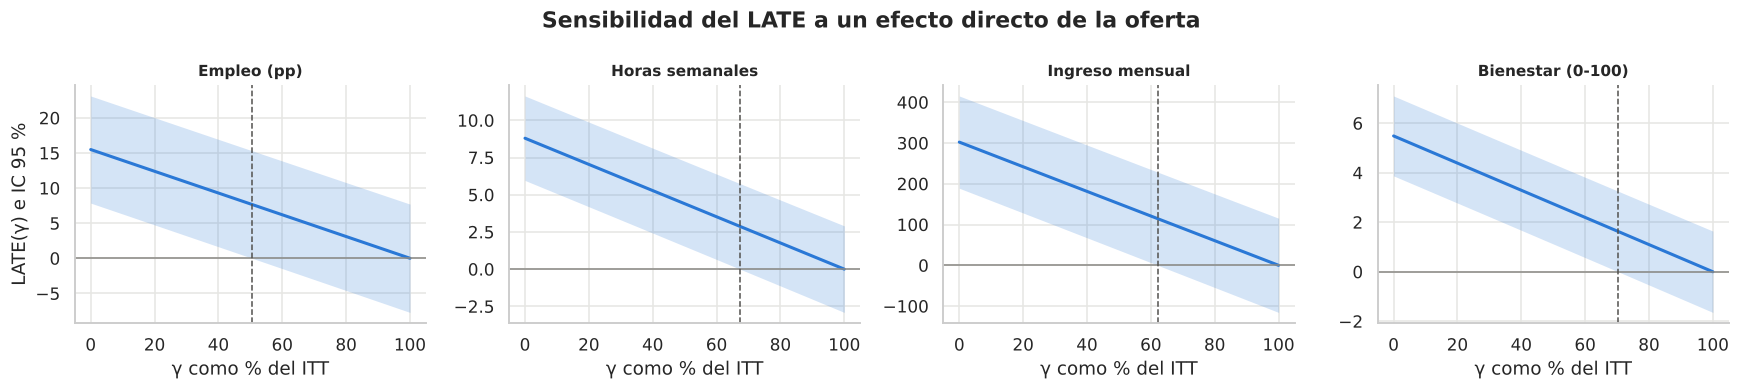

,punto de quiebre (γ como % del ITT)
Empleo (pp),50.563
Horas semanales,67.333
Ingreso mensual,62.186
Bienestar (0-100),70.354


In [13]:
from scipy.optimize import brentq

def late_gamma(y, gamma):
    d = df.dropna(subset=[y]).assign(y_adj=lambda t: t[y] - gamma * t[Z])
    r = IV2SLS.from_formula(f"y_adj ~ 1 + {CTRL} + [{D} ~ {Z}]", data=d).fit(cov_type="robust")
    return r.params[D], r.conf_int().loc[D].iloc[0], r.conf_int().loc[D].iloc[1]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
quiebre = {}
for ax, y in zip(axes, OUTCOMES):
    e = ESCALA.get(y, 1)
    itt, _ = itt_m3(df, y)
    fracs = np.linspace(0, 1, 41)
    res = np.array([late_gamma(y, f * itt / e) for f in fracs]) * e
    ax.fill_between(100 * fracs, res[:, 1], res[:, 2], color=COLORS[1], alpha=0.2, lw=0)
    ax.plot(100 * fracs, res[:, 0], color=COLORS[1], lw=2)
    ax.axhline(0, color=NEUTRAL, lw=1)
    # Punto de quiebre exacto: fracción f en que el límite inferior del IC del LATE cruza 0
    f_q = brentq(lambda f: late_gamma(y, f * itt / e)[1], 0, 1)
    quiebre[NOMBRES[y]] = 100 * f_q
    ax.axvline(100 * f_q, color="#52514e", ls="--", lw=1)
    ax.set_title(NOMBRES[y], fontsize=10); ax.set_xlabel("γ como % del ITT")
axes[0].set_ylabel("LATE(γ) e IC 95 %")
plt.suptitle("Sensibilidad del LATE a un efecto directo de la oferta", fontweight="bold")
plt.tight_layout(); plt.show()
display(pd.Series(quiebre, name="punto de quiebre (γ como % del ITT)").to_frame())

**Interpretación**

- El LATE sigue siendo significativo mientras el efecto directo de la oferta sea menor que **≈ 51 % del ITT para empleo**, 62 % para ingreso, 67 % para horas y 70 % para bienestar (puntos de quiebre calculados con precisión).
- **Empleo, horas e ingreso:** un efecto directo de esa magnitud, independiente del uso, es poco plausible. Habría que suponer que el solo hecho de ser sorteada (use o no la vacante) aumenta el empleo en ≈ 5 pp. El LATE laboral es robusto.
- **Bienestar:** es el resultado más expuesto a una violación de la exclusión, porque ser sorteada puede mejorar el ánimo o reducir la incertidumbre por sí solo. Aun así, el efecto directo tendría que explicar más de dos tercios del ITT (≈ 70 %) para anular el LATE. El ITT del bienestar no depende de este supuesto. Lo que es incierto es solo cuánto del efecto se atribuye al *uso*.

## 5.5 Síntesis de robustez y conclusión general

| Amenaza | Prueba | ¿Cambia la conclusión? |
|---|---|---|
| Especificación del modelo | Lin, logit, diferencias, winsorización p99 | No: puntos estables, IC excluyen 0 |
| Un centro influyente | Excluir un centro a la vez | No: efecto positivo y significativo en todas las muestras |
| Faltantes MAR | IPW con bootstrap | No: 188.5 frente a 188.8 |
| Faltantes MNAR | Lee, Manski, ajuste delta | No: incluso el peor caso (Manski) es positivo [106, 250] |
| Monotonicidad (IV) | Primera etapa en 37 subgrupos; desigualdades comprobables | Sin señales de violación (π ≥ 0.52; las 4 desigualdades se cumplen) |
| Exclusión (IV) | LATE(γ) (sensibilidad, no prueba) | LATE significativo mientras γ < 51-70 % del ITT |
| Margen intensivo | Cotas de Lee | **No identificado con precisión**: puede explicar de ≈ 0 % a ≈ 60 % del efecto en horas |

**Conclusión general del caso**

1. **Ofrecer horario ampliado de cuidado infantil** a madres postulantes aumenta el empleo en ~10 pp (+17 %), las horas en ~5.5 por semana, el ingreso laboral en ~190 u.m. al mes (+24 %) y el bienestar en ~3.4 puntos (0.33 DE). Estos resultados son robustos a todas las pruebas realizadas.
2. **Usar el servicio** (entre las cumplidoras, el 62 % de las postulantes) aumenta el empleo en ~15 pp y el ingreso en ~300 u.m. al mes. Este efecto depende además de la monotonicidad (compatible con las implicancias comprobables) y de la exclusión (no comprobable; el LATE sigue siendo significativo con efectos directos de hasta ≈ 51-70 % del ITT).
3. **Mecanismo:** el margen extensivo es un canal claro, porque el servicio permite trabajar a madres que de otro modo no lo harían o dejarían de hacerlo. La contribución del margen intensivo (más horas o ingreso entre quienes trabajarían igual) **no está identificada con precisión**: podría ir de casi nada a más de la mitad del efecto.
4. **No se encontró evidencia estadística de heterogeneidad** por restricción de cuidado ni por empleo previo, pero el experimento no tiene poder para detectar diferencias moderadas. No se recomienda focalizar el programa solo con esta evidencia.

**Limitaciones que persisten:** posible interferencia (20 % de no sorteadas usa el servicio), validez externa limitada a postulantes de 5 centros, horizonte temporal desconocido y ausencia de línea base de bienestar. Una evaluación costo-efectividad requeriría el costo por vacante, que no está en los datos.

## Referencias

1. Lee, D. S. (2009). Training, wages, and sample selection: Estimating sharp bounds on treatment effects. *Review of Economic Studies*, 76(3), 1071-1102. https://doi.org/10.1111/j.1467-937X.2009.00536.x
2. Lin, W. (2013). Agnostic notes on regression adjustments to experimental data: Reexamining Freedman's critique. *Annals of Applied Statistics*, 7(1), 295-318. https://doi.org/10.1214/12-AOAS583
3. Freedman, D. A. (2008). On regression adjustments to experimental data. *Advances in Applied Mathematics*, 40(2), 180-193. https://doi.org/10.1016/j.aam.2006.12.003
4. Manski, C. F. (1990). Nonparametric bounds on treatment effects. *American Economic Review*, 80(2), 319-323.
5. Balke, A. y Pearl, J. (1997). Bounds on treatment effects from studies with imperfect compliance. *Journal of the American Statistical Association*, 92(439), 1171-1176.
6. Kitagawa, T. (2015). A test for instrument validity. *Econometrica*, 83(5), 2043-2063. https://doi.org/10.3982/ECTA11974
7. Conley, T. G., Hansen, C. B. y Rossi, P. E. (2012). Plausibly exogenous. *Review of Economics and Statistics*, 94(1), 260-272. https://doi.org/10.1162/REST_a_00139